# Задача 8. Детектор большого объёма

Рассматривается детектор $R=15$ м с 2000 фотокатодами радиуса
10 см. Полный перебор имеет сложность $O(N_{\gamma}N_{\rm PMT})$.
Для ускорения центры ФЭУ один раз помещаются в `scipy.spatial.cKDTree`.
Затем ближайший центр ищется за $O(\log N_{\rm PMT})$, а точное
условие попадания проверяется по хордовому радиусу фотокатода.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from src.model import Detector, isotropic_directions

detector = Detector(R=15.0, N=2000, r=0.10, a=0.5)
radii = np.linalg.norm(detector.centers, axis=1)
assert detector.centers.shape == (2000, 3)
assert np.allclose(radii, detector.R)

print("Число ФЭУ:", detector.N)
print("Радиус детектора:", detector.R, "м")
print("Угловой радиус ФЭУ:", np.degrees(detector.angular_radius), "град")
print("Геометрическое покрытие:", detector.geometric_coverage_fraction)

Число ФЭУ: 2000
Радиус детектора: 15.0 м
Угловой радиус ФЭУ: 0.3819746928983493 град
Геометрическое покрытие: 0.02222246914129755


In [2]:
directions = isotropic_directions(25_000, np.random.default_rng(8101))
position = np.zeros(3)

start = time.perf_counter()
tree_result = detector.trace_photons(position, directions)
tree_time = time.perf_counter() - start

start = time.perf_counter()
full_scan_result = detector.trace_photons_scalar(position, directions)
full_scan_time = time.perf_counter() - start

assert np.array_equal(tree_result, full_scan_result)
speedup = full_scan_time / tree_time
print(f"k-d-дерево: {tree_time:.4f} с")
print(f"Полный перебор 2000 ФЭУ: {full_scan_time:.4f} с")
print(f"Ускорение: {speedup:.1f} раза")
print("Найдено попаданий:", np.count_nonzero(tree_result >= 0))

k-d-дерево: 0.0081 с
Полный перебор 2000 ФЭУ: 0.1661 с
Ускорение: 20.6 раза
Найдено попаданий: 539


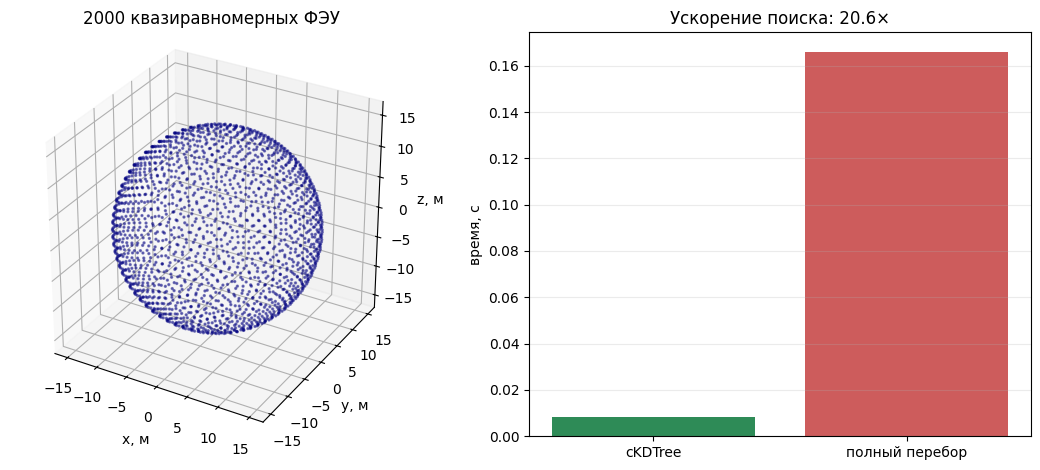

In [3]:
fig = plt.figure(figsize=(11, 4.8))
ax1 = fig.add_subplot(121, projection="3d")
ax1.scatter(*detector.centers.T, s=2, alpha=0.45, color="navy")
ax1.set(xlabel="x, м", ylabel="y, м", zlabel="z, м",
        title="2000 квазирaвномерных ФЭУ")
ax1.set_box_aspect((1, 1, 1))

ax2 = fig.add_subplot(122)
ax2.bar(["cKDTree", "полный перебор"], [tree_time, full_scan_time],
        color=["seagreen", "indianred"])
ax2.set(ylabel="время, с", title=f"Ускорение поиска: {speedup:.1f}×")
ax2.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig("figures/task8_large_detector.png", dpi=180, bbox_inches="tight")
plt.show()

**Вывод.** Пространственный индекс возвращает ровно те же
попадания, что и полный перебор, но проверяет только ближайший
центр и масштабируется значительно лучше при 2000 ФЭУ.